<a href="https://colab.research.google.com/github/sankeawthong/Project-1-Lita-Chatbot/blob/main/Lab12_Gymnasium_GridWorld%20(Assignment).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 12 — Teach a Robot the Rules of Its World

**Machine Learning (3 credits, 2-2-5) · Week 12 · School of Information Technology**

| | |
|---|---|
| **Time budget** | ~2 hours (in-lab) |
| **Learning objectives** | 1. Use Gymnasium's `reset` / `step` loop and read `observation_space` / `action_space` — 2. Implement a grid-world environment as a `gymnasium.Env` and validate it with `check_env` — 3. Compute discounted returns — 4. Measure a random-agent baseline (mean return, success rate, episode length) — 5. Check V and Q from the lecture in code |
| **Environments** | `FrozenLake-v1` (built into Gymnasium) · our own 4 × 4 delivery-robot **GridWorld** · a 1-D corridor you build yourself |
| **Grading** | Exercises 1–6 + AI-usage disclosure · self-checks give instant feedback |

> **The story.** A logistics company is testing a small delivery robot on a 4 × 4 floor. The door is at the far corner (+10), there is a puddle near the start that breaks the robot (−10), and every move costs battery (−1). Before anyone trains a clever agent, the team needs three things: **a simulator** that follows the rules exactly, **a way to score an episode**, and **a baseline** — how well does a robot that moves at random do?
>
> Everything you compute today matches the numbers in the Week 12 lecture: +5, 1.81, 6.2, 8, −23.9.

**First:** File → Save a copy in Drive, rename to `Lab12_<your_student_id>`.

---
## Setup

In [1]:
try:
    import gymnasium as gym
except ImportError:                       # Colab usually has it; install if not
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium"], check=True)
    import gymnasium as gym

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env

print("Gymnasium", gym.__version__, "· setup complete ✔")

Gymnasium 1.4.0 · setup complete ✔


---
## Part 1 · Gymnasium in five lines

Every Gymnasium environment has the same interface:

| call | returns | meaning |
|---|---|---|
| `env.observation_space` | e.g. `Discrete(16)` | what a state looks like |
| `env.action_space` | e.g. `Discrete(4)` | which actions are allowed |
| `env.reset(seed=…)` | `obs, info` | start an episode |
| `env.step(action)` | `obs, reward, terminated, truncated, info` | do one action |

`FrozenLake` is a 4 × 4 frozen lake: **S** start, **F** frozen (safe), **H** hole (episode ends, reward 0), **G** goal (reward +1). Actions: 0 = left, 1 = down, 2 = right, 3 = up.

In [2]:
env = gym.make("FrozenLake-v1", is_slippery=False, render_mode="ansi")
print("observation space:", env.observation_space)
print("action space     :", env.action_space)

obs, info = env.reset(seed=0)
print("start state:", obs)
print(env.render())

observation space: Discrete(16)
action space     : Discrete(4)
start state: 0

SFFF
FHFH
FFFH
HFFG



In [3]:
# Walk a safe path by hand: down, down, right, right, down, right
for action in [1, 1, 2, 2, 1, 2]:
    obs, reward, terminated, truncated, info = env.step(action)
    print(f"action {action} → state {obs:2d}, reward {reward}, terminated {terminated}")
print(env.render())

action 1 → state  4, reward 0, terminated False
action 1 → state  8, reward 0, terminated False
action 2 → state  9, reward 0, terminated False
action 2 → state 10, reward 0, terminated False
action 1 → state 14, reward 0, terminated False
action 2 → state 15, reward 1, terminated True
  (Right)
SFFF
FHFH
FFFH
HFFG



**What to notice:** the reward is 0 for every step and +1 only at the goal — a **delayed** reward. `terminated` becomes `True` when the episode really ends.

---
## Part 2 · A random agent on FrozenLake — dry vs slippery

`env.action_space.sample()` returns a random legal action. That is a complete (if useless) agent. With `is_slippery=True` the lake behaves like the lecture's slippery floor: the robot moves in the intended direction only 1/3 of the time.

In [4]:
def random_success_rate(slippery, n_episodes=1000):
    env = gym.make("FrozenLake-v1", is_slippery=slippery)
    env.action_space.seed(0)
    wins = 0
    for ep in range(n_episodes):
        obs, info = env.reset(seed=ep)
        done = False
        while not done:
            obs, reward, terminated, truncated, info = env.step(env.action_space.sample())
            done = terminated or truncated
        wins += reward == 1.0
    return wins / n_episodes

for slip in (False, True):
    print(f"is_slippery={slip!s:5}: random agent reaches the goal in {random_success_rate(slip):.1%} of episodes")

is_slippery=False: random agent reaches the goal in 1.5% of episodes
is_slippery=True : random agent reaches the goal in 1.2% of episodes


A random agent almost never succeeds. Any learning method has to beat these numbers — that is what a **baseline** is for.

---
## Part 3 · Build the delivery-robot GridWorld

Our own environment, written as a subclass of `gymnasium.Env`. Read the code — you will write a smaller one yourself in Exercise 2.

* **State:** the robot's cell as one number, `row * 4 + col` (0 … 15) → `Discrete(16)`
* **Actions:** 0 = up, 1 = right, 2 = down, 3 = left → `Discrete(4)`
* **Rewards:** −1 per move · +10 at the door (3, 3) · −10 in the puddle (1, 2). Bumping into an edge: stay in place, −1.
* **Ends:** at the door or the puddle (`terminated`), or after 50 steps (`truncated`).

In [5]:
MOVES = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}     # up, right, down, left
NAMES = ["up", "right", "down", "left"]

class GridWorldEnv(gym.Env):
    metadata = {"render_modes": ["ansi"]}

    def __init__(self, size=4, goal=(3, 3), puddle=(1, 2), max_steps=50):
        super().__init__()
        self.size, self.goal, self.puddle, self.max_steps = size, goal, puddle, max_steps
        self.observation_space = spaces.Discrete(size * size)
        self.action_space = spaces.Discrete(4)

    def _obs(self):
        return self.pos[0] * self.size + self.pos[1]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)                  # seeds self.np_random
        self.pos, self.t = (0, 0), 0
        return self._obs(), {}

    def step(self, action):
        dr, dc = MOVES[int(action)]
        r, c = self.pos[0] + dr, self.pos[1] + dc
        if 0 <= r < self.size and 0 <= c < self.size:      # inside the grid → move
            self.pos = (r, c)
        self.t += 1
        if self.pos == self.goal:
            reward, terminated = 10.0, True
        elif self.pos == self.puddle:
            reward, terminated = -10.0, True
        else:
            reward, terminated = -1.0, False
        truncated = self.t >= self.max_steps and not terminated
        return self._obs(), reward, terminated, truncated, {}

    def render(self):
        rows = []
        for r in range(self.size):
            rows.append(" ".join("R" if (r, c) == self.pos else "G" if (r, c) == self.goal
                                 else "P" if (r, c) == self.puddle else "." for c in range(self.size)))
        return "\n".join(rows)

grid = GridWorldEnv()
check_env(grid, skip_render_check=True)        # Gymnasium's own tests — silent if all is well
print("check_env passed ✔")
obs, info = grid.reset(seed=0)
print(grid.render())

check_env passed ✔
R . . .
. . P .
. . . .
. . . G


In [6]:
# Walk the best path from the lecture: right ×3, down ×3
obs, info = grid.reset(seed=0)
rewards = []
for a in [1, 1, 1, 2, 2, 2]:
    obs, r, terminated, truncated, info = grid.step(a)
    rewards.append(r)
    print(f"{NAMES[a]:5s} → state {obs:2d}  reward {r:+.0f}  terminated {terminated}")
print("rewards:", rewards, "· return (γ = 1):", sum(rewards))
print(grid.render())

right → state  1  reward -1  terminated False
right → state  2  reward -1  terminated False
right → state  3  reward -1  terminated False
down  → state  7  reward -1  terminated False
down  → state 11  reward -1  terminated False
down  → state 15  reward +10  terminated True
rewards: [-1.0, -1.0, -1.0, -1.0, -1.0, 10.0] · return (γ = 1): 5.0
. . . .
. . P .
. . . .
. . . R


**Result:** five moves at −1 and +10 at the door — return **+5**, exactly as on the lecture slides.

---
## Part 4 · Returns and the discount factor γ

$G = r_1 + \gamma r_2 + \gamma^2 r_3 + \dots$ — the first reward counts fully; a reward $k$ steps later is multiplied by $\gamma^k$. You will write `discounted_return` in **Exercise 1**; here is how γ changes the value of the same best path.

In [7]:
best_rewards = [-1, -1, -1, -1, -1, 10]
for g in [1.0, 0.99, 0.9, 0.5]:
    weights = g ** np.arange(len(best_rewards))
    print(f"γ = {g:4}: weights {np.round(weights, 2)}  →  G = {np.dot(weights, best_rewards):+.2f}")

γ =  1.0: weights [1. 1. 1. 1. 1. 1.]  →  G = +5.00
γ = 0.99: weights [1.   0.99 0.98 0.97 0.96 0.95]  →  G = +4.61
γ =  0.9: weights [1.   0.9  0.81 0.73 0.66 0.59]  →  G = +1.81
γ =  0.5: weights [1.   0.5  0.25 0.12 0.06 0.03]  →  G = -1.62


Same path, four values: +5, +4.61, +1.81, −1.62. With γ = 0.5 the robot is so short-sighted that the whole delivery looks like a loss.

---
## Part 5 · The random-agent baseline

Run 1,000 episodes with random actions and record the return, the length and how each episode ended.

In [8]:
rng = np.random.default_rng(0)
rows = []
for ep in range(1000):
    obs, info = grid.reset(seed=ep)
    G, steps, done = 0.0, 0, False
    while not done:
        obs, r, terminated, truncated, info = grid.step(int(rng.integers(4)))
        G += r; steps += 1
        done = terminated or truncated
    ending = "door" if r == 10 else "puddle" if r == -10 else "time-out"
    rows.append({"return": G, "steps": steps, "ending": ending})
base = pd.DataFrame(rows)

print(f"mean return {base['return'].mean():.1f} (std {base['return'].std():.1f}) · mean length {base['steps'].mean():.1f} steps")
for ending, share in base["ending"].value_counts(normalize=True).items():
    print(f"{ending:9s} {share:.1%}")

mean return -23.9 (std 13.1) · mean length 18.8 steps
puddle    78.1%
door      18.2%
time-out  3.7%


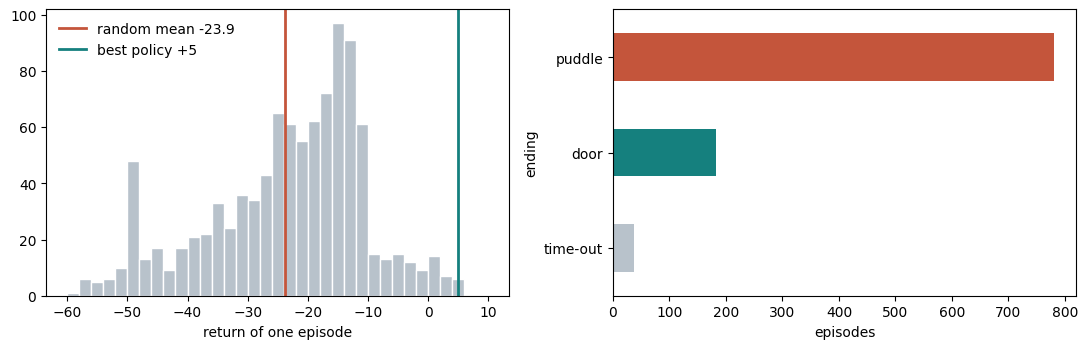

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].hist(base["return"], bins=np.arange(-60, 12, 2), color="#B8C2CB", edgecolor="white")
axs[0].axvline(base["return"].mean(), color="#C4553B", lw=2, label=f"random mean {base['return'].mean():.1f}")
axs[0].axvline(5, color="#15807E", lw=2, label="best policy +5")
axs[0].set_xlabel("return of one episode"); axs[0].legend(frameon=False)
base["ending"].value_counts().reindex(["puddle", "door", "time-out"]).plot.barh(ax=axs[1], color=["#C4553B", "#15807E", "#B8C2CB"])
axs[1].invert_yaxis(); axs[1].set_xlabel("episodes"); plt.tight_layout(); plt.show()

**Reading it:** the puddle is two moves from the start and the door six, so a random walk falls in the puddle about **78%** of the time and reaches the door only about **18%**. Mean return ≈ **−23.9** vs **+5** for the best policy. That gap is what learning has to close.

---
## Part 6 · Values: check the lecture's V and Q

When we know the rules (the **model**), we can compute values directly. `model(pos, a)` returns where an action leads and its reward — the same rules as `step`, without changing the environment. `value_iteration` repeats *V(s) = max over actions of [reward + γ · V(next)]* until nothing changes (the lecture video). Both accept a different `model_fn` if you change the rules (Exercise 6c).

In [10]:
SIZE, GOAL, PUDDLE = 4, (3, 3), (1, 2)
TERMINAL = {GOAL, PUDDLE}

def model(pos, a):
    # Rules of the GridWorld: returns (next_pos, reward, done) for action a in cell pos.
    dr, dc = MOVES[a]
    r, c = pos[0] + dr, pos[1] + dc
    nxt = (r, c) if 0 <= r < SIZE and 0 <= c < SIZE else pos
    if nxt == GOAL:   return nxt, 10.0, True
    if nxt == PUDDLE: return nxt, -10.0, True
    return nxt, -1.0, False

def backup(V, pos, a, gamma, model_fn=model):
    nxt, r, done = model_fn(pos, a)
    return r + (0.0 if done else gamma * V[nxt])

def value_iteration(gamma=0.9, tol=1e-9, model_fn=model):
    V = np.zeros((SIZE, SIZE))
    for sweep in range(1, 1000):
        V_new = V.copy()
        for r in range(SIZE):
            for c in range(SIZE):
                if (r, c) not in TERMINAL:
                    V_new[r, c] = max(backup(V, (r, c), a, gamma, model_fn) for a in range(4))
        if np.abs(V_new - V).max() < tol:
            return V_new, sweep
        V = V_new

def evaluate_random_policy(gamma=0.9, tol=1e-10):
    V = np.zeros((SIZE, SIZE))
    while True:
        V_new = V.copy()
        for r in range(SIZE):
            for c in range(SIZE):
                if (r, c) not in TERMINAL:
                    V_new[r, c] = np.mean([backup(V, (r, c), a, gamma) for a in range(4)])
        if np.abs(V_new - V).max() < tol:
            return V_new
        V = V_new

V_star, sweeps = value_iteration(0.9)
V_rand = evaluate_random_policy(0.9)
print(f"value iteration converged after {sweeps} sweeps")
print("V* (γ = 0.9):\n", V_star.round(2))
print("V under the random policy:\n", V_rand.round(2))

value iteration converged after 7 sweeps
V* (γ = 0.9):
 [[ 1.81  3.12  4.58  6.2 ]
 [ 3.12  4.58  0.    8.  ]
 [ 4.58  6.2   8.   10.  ]
 [ 6.2   8.   10.    0.  ]]
V under the random policy:
 [[-9.36 -9.38 -9.4  -8.56]
 [-9.07 -9.09  0.   -7.08]
 [-8.34 -7.51 -5.5  -1.4 ]
 [-7.69 -6.02 -1.09  0.  ]]


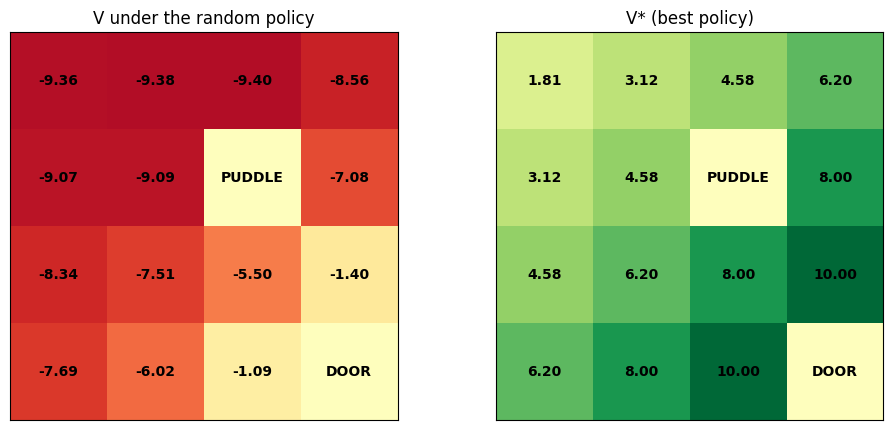

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, V, t in [(axs[0], V_rand, "V under the random policy"), (axs[1], V_star, "V* (best policy)")]:
    im = ax.imshow(V, cmap="RdYlGn", vmin=-10, vmax=10)
    for r in range(SIZE):
        for c in range(SIZE):
            label = "DOOR" if (r, c) == GOAL else "PUDDLE" if (r, c) == PUDDLE else f"{V[r, c]:.2f}"
            ax.text(c, r, label, ha="center", va="center", fontsize=10, fontweight="bold")
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**What to notice:** the bottom row of V* reads 6.2 · 8 · 10 — the lecture's hand calculation. The start is worth 1.81, the discounted return of the 6-step path from Part 4. Under the random policy every cell is negative: **V depends on the policy.**

---
# Exercises (graded)

Fill in every `...`. Run the self-check cell after each exercise.

### Exercise 1 · Discounted return

Write `discounted_return(rewards, gamma)` that returns $\sum_k \gamma^k r_{k+1}$ (the first reward has weight $\gamma^0 = 1$).

In [ ]:
def discounted_return(rewards, gamma):
    ...

print(discounted_return([-1, -1, 10], 0.9))           # lecture: 6.2
print(discounted_return(best_rewards, 0.9))            # lecture: 1.81

In [ ]:
# ✅ Self-check — Exercise 1
assert abs(discounted_return([-1, -1, 10], 0.9) - 6.2) < 1e-9, "From (2, 1): −1 + 0.9 × (−1) + 0.81 × 10 should be 6.2. Is the first reward multiplied by γ⁰ = 1?"
assert abs(discounted_return(best_rewards, 1.0) - 5) < 1e-9, "With γ = 1 the best path should give +5."
assert abs(discounted_return(best_rewards, 0.9) - V_star[0, 0]) < 1e-9, "The discounted return of the best path should equal V*(start) = 1.81."
assert discounted_return([], 0.9) == 0, "An empty episode has return 0."
print("Exercise 1 ✔  — 6.2 and 1.81, as on the slides")

### Exercise 2 · Build your own environment: a 1-D corridor

A corridor of 5 cells, numbered 0 … 4. The robot starts in cell 0; the door is cell 4.

* Actions: **0 = left, 1 = right** → `Discrete(2)`; states: `Discrete(5)`
* Every move costs −1; reaching cell 4 gives **+10** instead and ends the episode (`terminated = True`)
* Moving left from cell 0 keeps the robot in cell 0 (still −1)
* After `max_steps` steps without reaching the door: `truncated = True`

Complete the three methods.

In [ ]:
class CorridorEnv(gym.Env):
    def __init__(self, length=5, max_steps=20):
        super().__init__()
        self.length, self.max_steps = length, max_steps
        self.observation_space = ...            # Discrete(length)
        self.action_space = ...                 # Discrete(2)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.pos, self.t = 0, 0
        return ..., {}                          # the first observation

    def step(self, action):
        move = 1 if action == 1 else -1
        self.pos = ...                          # stay inside 0 … length − 1
        self.t += 1
        terminated = ...                        # reached the last cell?
        reward = ...                            # +10 at the door, otherwise −1
        truncated = ...                         # time limit, and not terminated
        return self.pos, reward, terminated, truncated, {}

corridor = CorridorEnv()

In [ ]:
# ✅ Self-check — Exercise 2
check_env(CorridorEnv(), skip_render_check=True)
env2 = CorridorEnv(); obs, _ = env2.reset(seed=0)
assert obs == 0, "reset() should put the robot in cell 0."
obs, r, term, trunc, _ = env2.step(0)
assert (obs, r, term) == (0, -1.0, False), "Moving left from cell 0 should stay in cell 0 with reward −1."
out = [env2.step(1) for _ in range(4)]
assert [o[1] for o in out] == [-1.0, -1.0, -1.0, 10.0], "Four moves right: rewards should be −1, −1, −1, +10."
assert out[-1][2] is True or out[-1][2] == True, "Reaching cell 4 should set terminated = True."
env3 = CorridorEnv(max_steps=20); env3.reset(seed=0)
for _ in range(20): obs, r, term, trunc, _ = env3.step(0)
assert trunc and not term, "After 20 steps without reaching the door: truncated = True, terminated = False."
print("Exercise 2 ✔  — your environment passes Gymnasium's check_env and follows the rules")

### Exercise 3 · A reusable `evaluate` function

Complete `evaluate(env, policy, n_episodes)`. A **policy** here is a function `policy(obs, rng) → action`. Return the mean return (γ = 1), the success rate (the episode ended with the +10 reward) and the mean episode length. Then evaluate the random policy — you should reproduce Part 5.

In [ ]:
def evaluate(env, policy, n_episodes=1000, seed=0):
    rng = np.random.default_rng(seed)
    returns, lengths, wins = [], [], 0
    for ep in range(n_episodes):
        obs, info = env.reset(seed=ep)
        G, steps, done = 0.0, 0, False
        while not done:
            action = ...
            obs, reward, terminated, truncated, info = ...
            G += reward; steps += 1
            done = ...
        returns.append(G); lengths.append(steps)
        wins += ...                              # 1 if this episode reached the door
    return {"mean_return": float(np.mean(returns)), "success_rate": wins / n_episodes,
            "mean_length": float(np.mean(lengths))}

random_policy = lambda obs, rng: int(rng.integers(4))
res_random = evaluate(GridWorldEnv(), random_policy)
res_random

In [ ]:
# ✅ Self-check — Exercise 3
assert abs(res_random["mean_return"] - base["return"].mean()) < 1e-9, "Your mean return should match Part 5 exactly (same seeds)."
assert abs(res_random["success_rate"] - (base["ending"] == "door").mean()) < 1e-9, "Success = the episode ended at the door (+10)."
assert abs(res_random["mean_length"] - base["steps"].mean()) < 1e-9, "Mean length should match Part 5."
print(f"Exercise 3 ✔  — random baseline: mean return {res_random['mean_return']:.1f}, "
      f"success {res_random['success_rate']:.0%}, {res_random['mean_length']:.1f} steps")

### Exercise 4 · Beat the baseline with a hand-written policy

Write `my_policy(obs, rng)` — no learning, just a rule — that reaches the door every time **without** touching the puddle. Hint: `row, col = divmod(obs, 4)`; actions are 0 = up, 1 = right, 2 = down, 3 = left.

In [ ]:
def my_policy(obs, rng):
    row, col = divmod(obs, 4)
    ...

res_mine = evaluate(GridWorldEnv(), my_policy, n_episodes=100)
res_mine

In [ ]:
# ✅ Self-check — Exercise 4
assert res_mine["success_rate"] == 1.0, "Your policy should reach the door in every episode."
assert res_mine["mean_return"] == 5.0 and res_mine["mean_length"] == 6.0, "The shortest safe path is 6 moves (return +5). Is there a detour?"
print(f"Exercise 4 ✔  — your rule: +5 every time vs {res_random['mean_return']:.1f} for random")

### Exercise 5 · Q by hand, then by code

The robot is at **(3, 1)** with γ = 0.9. Using `model` and `V_star` from Part 6, compute **Q((3, 1), a) = reward + γ · V*(next cell)** for all four actions (0 = up, 1 = right, 2 = down, 3 = left). Then pick the best action. First write your hand answer from the lecture, then compute it.

In [ ]:
pos, gamma = (3, 1), 0.9
q_values = np.array([...  for a in range(4)])     # use model(pos, a) and V_star
best_action = ...                                   # index of the largest Q
print({NAMES[a]: round(float(q), 2) for a, q in enumerate(q_values)}, "→ best:", NAMES[best_action])

In [ ]:
# ✅ Self-check — Exercise 5
assert np.allclose(q_values, [4.58, 8.0, 6.2, 4.58], atol=0.005), "Expected up 4.58 · right 8.00 · down 6.20 · left 4.58 (down hits the wall and stays)."
assert best_action == 1, "The best action is the one with the largest Q."
assert abs(q_values.max() - V_star[3, 1]) < 1e-9, "V*(s) should equal the largest Q(s, a)."
print("Exercise 5 ✔  — Q from code = Q from the slide; V*(3, 1) = max Q = 8")

### Exercise 6 · Open-ended (choose any two of a–c, plus d)

**(a) A slippery floor.** Make a `SlipperyGridWorld(GridWorldEnv)` whose `step` replaces the chosen action with a random **perpendicular** one with probability 0.2 (0.1 each side; use `self.np_random`). Evaluate the random policy and your `my_policy` from Exercise 4. Which suffers more, and why?

**(b) Patience.** Run `value_iteration` with γ = 0.5, 0.9 and 0.99. Report V*(start) for each, and check whether the best action at the start changes.

**(c) Reward design.** Remove the step cost (every ordinary move gives 0 instead of −1) and re-run the random baseline and value iteration (γ = 0.9). What happens to V*, and why is a step cost useful?

**(d) Write-up (required, at least 3 sentences).** What did the baseline tell you, and what would you tell the logistics team before they train a learning agent?

In [ ]:
# (a), (b) or (c) — your code here
...

✍️ **(d) Write-up:**

*(write here — at least 3 sentences)*

---
## AI-usage disclosure (required)

Did you use an AI assistant (ChatGPT, Claude, Copilot, …) for any part of this lab? If yes: which tool, for which exercise, and what did you change in what it gave you? If no, write "No AI used".

*(write here)*

---
## Submitting
1. Runtime → Restart session and run all — no errors, every self-check ✔.
2. File → Download → `.ipynb`.
3. Upload `Lab12_<your_student_id>.ipynb` to the Lab 12 assignment on **MS Teams**.